In [182]:
import time
start_time = time.time()

# ECE 3715 Mini-Project 3

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.stats as stats
import statsmodels.api as sm
import mp3lib
from scipy.integrate import quad, dblquad, trapezoid
from mp3lib import sample_mean_cov, is_valid_covariance

from scipy.special import gamma
from scipy.stats import kstest
import statsmodels.api as sm

SEED = 1137852084
rng = np.random.default_rng(SEED)

rng_step1 = rng.spawn(1)[0]
rng_step2 = rng.spawn(1)[0]
rng_step3 = rng.spawn(1)[0]
rng_step4 = rng.spawn(1)[0]
rng_step5 = rng.spawn(1)[0]
rng_step6 = rng.spawn(1)[0]
rng_step7 = rng.spawn(1)[0]
rng_step8 = rng.spawn(1)[0]
rng_bonus_a = rng.spawn(1)[0]
rng_bonus_b = rng.spawn(1)[0]

print(f"Kernel initialized with SEED = {SEED}")

SEED = 1137852084


## Step 1: Two variables at once

The joint density is $f_{X,Y}(x,y)=x+y$ on $0\le x\le 1$ and $0\le y\le 1$, and zero everywhere else.

### 1.1 Checking the density and finding the marginals

The density is nonnegative, and its integral over the unit square is

$$\int_0^1\int_0^1(x+y)\,dy\,dx
=\int_0^1\left(x+\frac12\right)dx
=\frac12+\frac12=1.$$

Integrating the joint density over $y$ gives

$$f_X(x)=\int_0^1(x+y)dy=x+\frac12, \quad 0\le x\le 1.$$

Similarly,

$$f_Y(y)=\int_0^1(x+y)dx=y+\frac12, \quad 0\le y\le 1.$$

### 1.2 Conditional density

$$f_{Y\mid X}(y\mid x)=\frac{f_{X,Y}(x,y)}{f_X(x)}=\frac{x+y}{x+1/2}.$$

At $x=0.3$, $f_X(0.3)=0.8$, so

$$f_{Y\mid X}(y\mid 0.3)=\frac{0.3+y}{0.8}, \quad 0\le y\le1.$$

The code checks the integral numerically and plots this density in Figure 1.


In [184]:
def joint_density(x, y):
    return x + y

integral, integration_error = dblquad(
    lambda y, x: joint_density(x, y), 0, 1, lambda x: 0, lambda x: 1
)
x_grid = np.linspace(0, 1, 501)
y_grid = np.linspace(0, 1, 501)
joint_grid = x_grid[:, None] + y_grid[None, :]
num_fx = trapezoid(joint_grid, y_grid, axis=1)
num_fy = trapezoid(joint_grid, x_grid, axis=0)
theory_fx = x_grid + 0.5
theory_fy = y_grid + 0.5
x0 = 0.3
conditional_pdf = lambda y: (x0 + y) / (x0 + 0.5)
conditional_integral, conditional_error = quad(conditional_pdf, 0, 1)

print(f"Joint density integral = {integral:.10f}; difference from 1 = {abs(integral-1):.3e}; quadrature error estimate = {integration_error:.3e}")
print(f"Marginal X max grid difference = {np.max(np.abs(num_fx-theory_fx)):.3e}")
print(f"Marginal Y max grid difference = {np.max(np.abs(num_fy-theory_fy)):.3e}")
print(f"f_X(0.3) = {x0+0.5:.6f}")
print(f"Conditional integral at X=0.3 = {conditional_integral:.10f}; difference from 1 = {abs(conditional_integral-1):.3e}")

Joint density integral = 1.0000000000; difference from 1 = 0.000e+00; quadrature error estimate = 1.663e-14
Marginal X max grid difference = 2.220e-16
Marginal Y max grid difference = 8.882e-16
f_X(0.3) = 0.800000
Conditional integral at X=0.3 = 1.0000000000; difference from 1 = 1.110e-16


### 1.3 Expected values, variance, covariance, and correlation

Using the marginal densities,

$$E[X]=\int_0^1x\left(x+\frac12\right)dx=\frac13+\frac14=\frac7{12}, \quad E[Y]=\frac7{12}.$$

$$E[X^2]=\int_0^1x^2\left(x+\frac12\right)dx=\frac14+\frac16=\frac5{12}.$$

$$E[XY]=\int_0^1\int_0^1xy(x+y)\,dy\,dx
=\frac16+\frac16=\frac13.$$

$$\operatorname{Var}(X)=E[X^2]-E[X]^2
=\frac5{12}-\left(\frac7{12}\right)^2=\frac{11}{144}.$$

By symmetry, $\operatorname{Var}(Y)=11/144$. Then

$$\operatorname{Cov}(X,Y)=E[XY]-E[X]E[Y]
=\frac13-\frac{49}{144}=-\frac1{144}.$$

$$\rho_{XY}=\frac{\operatorname{Cov}(X,Y)}{\sqrt{\operatorname{Var}(X)\operatorname{Var}(Y)}}
=\frac{-1/144}{11/144}=-\frac1{11}.$$

The next cell checks these calculations with numerical integration.


In [185]:
def integrate_joint(g):
    value, error_est = dblquad(
        lambda y, x: g(x, y) * joint_density(x, y),
        0, 1, lambda x: 0, lambda x: 1,
    )
    return value, error_est

ex_quad, _ = integrate_joint(lambda x, y: x)
ey_quad, _ = integrate_joint(lambda x, y: y)
exy_quad, _ = integrate_joint(lambda x, y: x*y)
ex2_quad, _ = integrate_joint(lambda x, y: x*x)
ey2_quad, _ = integrate_joint(lambda x, y: y*y)
varx_quad = ex2_quad - ex_quad**2
vary_quad = ey2_quad - ey_quad**2
cov_quad = exy_quad - ex_quad*ey_quad
rho_quad = cov_quad / np.sqrt(varx_quad*vary_quad)

analytical = {"E[X]": 7/12, "E[Y]": 7/12, "E[XY]": 1/3,
              "Var(X)": 11/144, "Cov(X,Y)": -1/144, "rho": -1/11}
quadrature = {"E[X]": ex_quad, "E[Y]": ey_quad, "E[XY]": exy_quad,
              "Var(X)": varx_quad, "Cov(X,Y)": cov_quad, "rho": rho_quad}
quad_table = pd.DataFrame([
    {"quantity": key, "analytical": analytical[key], "quadrature": quadrature[key],
     "absolute difference": abs(quadrature[key]-analytical[key])}
    for key in analytical
])
print("Numerical integration compared with hand-derived values:")
print(quad_table.to_string(index=False, float_format=lambda v: f"{v:.9g}"))


Numerical integration compared with hand-derived values:
quantity     analytical     quadrature  absolute difference
    E[X]    0.583333333    0.583333333       1.11022302e-16
    E[Y]    0.583333333    0.583333333       1.11022302e-16
   E[XY]    0.333333333    0.333333333       1.11022302e-16
  Var(X)   0.0763888889   0.0763888889       5.55111512e-17
Cov(X,Y) -0.00694444444 -0.00694444444       1.90819582e-16
     rho  -0.0909090909  -0.0909090909       2.58126853e-15


### 1.4 Rejection sampling

For the rejection sampler, we draw points uniformly on the unit square. Since $x+y\le 2$, we can use $M=2$ as the bound. We accept each point with probability $(x+y)/2$ and keep going until we have $10^6$ accepted samples. Since the density integrates to 1, the expected acceptance rate is $1/2=50\%$.


In [186]:
def rejection_sample_xy(n, rng, batch_size=250_000):
    accepted_chunks = []
    accepted_count = 0
    proposed_count = 0
    all_accepted_count = 0
    while accepted_count < n:
        proposals = rng.random((batch_size, 3))
        x = proposals[:, 0]
        y = proposals[:, 1]
        is_accepted = 2 * proposals[:, 2] <= x + y
        accepted = proposals[is_accepted, :2]
        proposed_count += batch_size
        all_accepted_count += accepted.shape[0]
        keep = min(accepted.shape[0], n-accepted_count)
        accepted_chunks.append(accepted[:keep])
        accepted_count += keep
    return np.vstack(accepted_chunks), all_accepted_count/proposed_count

N1 = 1_000_000
xy_samples, acceptance_rate = rejection_sample_xy(N1, rng_step1)
x = xy_samples[:, 0]
y = xy_samples[:, 1]
mx, my = x.mean(), y.mean()
varx = x.var(ddof=1)
vary = y.var(ddof=1)
covxy = np.cov(x, y, ddof=1)[0, 1]
correlation = covxy / np.sqrt(varx*vary)
xy_product = x*y

# Estimated standard errors for the sample statistics.
mean_x_se = x.std(ddof=1) / np.sqrt(N1)
mean_y_se = y.std(ddof=1) / np.sqrt(N1)
xy_se = xy_product.std(ddof=1) / np.sqrt(N1)
if_vx = (x-mx)**2-varx
if_vy = (y-my)**2-vary
if_cov = (x-mx)*(y-my)-covxy
varx_se = np.sqrt(np.mean(if_vx**2) / N1)
cov_se = np.sqrt(np.mean(if_cov**2) / N1)
if_rho = if_cov/np.sqrt(varx*vary) - 0.5*correlation*(if_vx/varx + if_vy/vary)
rho_se = np.sqrt(np.mean(if_rho**2)/N1)

simulation = {"E[X]": mx, "E[Y]": my, "E[XY]": xy_product.mean(),
              "Var(X)": varx, "Cov(X,Y)": covxy, "rho": correlation}
standard_errors = {"E[X]": mean_x_se, "E[Y]": mean_y_se, "E[XY]": xy_se,
                   "Var(X)": varx_se, "Cov(X,Y)": cov_se, "rho": rho_se}
sim_table = pd.DataFrame([
    {"quantity": key, "analytic": analytical[key], "simulated": simulation[key],
     "abs difference": abs(simulation[key]-analytical[key]),
     "approx standard error": standard_errors[key]}
    for key in analytical
])
print(f"Samples accepted = {N1:,}; empirical acceptance rate = {acceptance_rate:.6f}; expected ≈ 0.500000")
print(sim_table.to_string(index=False, float_format=lambda v: f"{v:.8f}"))


Samples accepted = 1,000,000; empirical acceptance rate = 0.500193; expected ≈ 0.500000
quantity    analytic   simulated  abs difference  approx standard error
    E[X]  0.58333333  0.58357354      0.00024021             0.00027622
    E[Y]  0.58333333  0.58344450      0.00011116             0.00027634
   E[XY]  0.33333333  0.33341946      0.00008612             0.00023553
  Var(X)  0.07638889  0.07629806      0.00009082             0.00007629
Cov(X,Y) -0.00694444 -0.00706332      0.00011888             0.00007475
     rho -0.09090909 -0.09253535      0.00162626             0.00097059


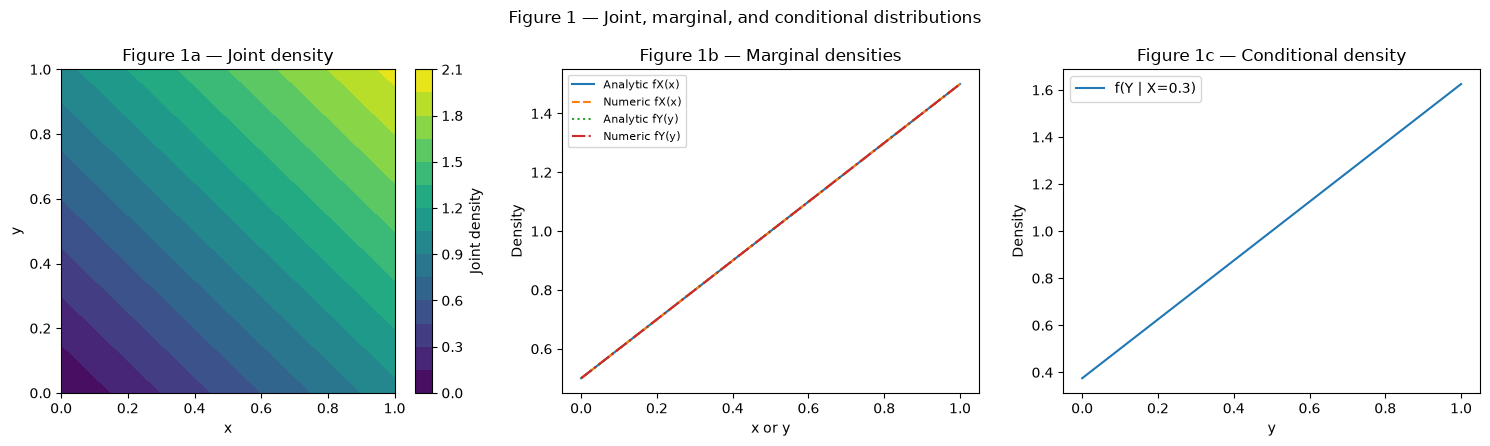

In [187]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
contour = axes[0].contourf(x_grid, y_grid, joint_grid.T, levels=15)
fig.colorbar(contour, ax=axes[0], label="Joint density")
axes[0].set(title="Figure 1a — Joint density", xlabel="x", ylabel="y")

axes[1].plot(x_grid, theory_fx, label="Analytic fX(x)")
axes[1].plot(x_grid, num_fx, "--", label="Numeric fX(x)")
axes[1].plot(y_grid, theory_fy, ":", label="Analytic fY(y)")
axes[1].plot(y_grid, num_fy, "-.", label="Numeric fY(y)")
axes[1].set(title="Figure 1b — Marginal densities", xlabel="x or y", ylabel="Density")
axes[1].legend(fontsize=8)

axes[2].plot(y_grid, conditional_pdf(y_grid), label="f(Y | X=0.3)")
axes[2].set(title="Figure 1c — Conditional density", xlabel="y", ylabel="Density")
axes[2].legend()
fig.suptitle("Figure 1 — Joint, marginal, and conditional distributions")
plt.tight_layout()
plt.show()


**Figure 1.** The joint density is highest near $(1,1)$. The numerical marginals line up with the formulas, and the conditional density at $x=0.3$ integrates to 1, as shown in the output.

The correlation is slightly negative because $E[Y\mid X=x]=(x/2+1/3)/(x+1/2)$ decreases as $x$ increases. This means that, even though the joint density rises toward $(1,1)$, a larger $X$ goes with a slightly smaller average value of $Y$.


# Step 2: Uncorrelated Does Not Mean Independent

## 2.1 Analytic Derivation for $X \sim \text{Uniform}(-1, 1)$ and $Y = X^2$

Since $X \sim \text{Uniform}(-1, 1)$, its probability density function is:
$$f_X(x) = \frac{1}{2}, \quad -1 \le x \le 1$$

**Mean and Variance of $X$:**
$$E[X] = \int_{-1}^{1} x \cdot \frac{1}{2}\,dx = \left[\frac{x^2}{4}\right]_{-1}^{1} = \frac{1}{4} - \frac{1}{4} = 0$$

$$E[X^2] = \int_{-1}^{1} x^2 \cdot \frac{1}{2}\,dx = \left[\frac{x^3}{6}\right]_{-1}^{1} = \frac{1}{6} - \left(-\frac{1}{6}\right) = \frac{1}{3}$$

$$\text{Var}(X) = E[X^2] - (E[X])^2 = \frac{1}{3} - 0 = \frac{1}{3}$$

**Mean and Variance of $Y = X^2$:**
$$E[Y] = E[X^2] = \frac{1}{3}$$

$$E[Y^2] = E[X^4] = \int_{-1}^{1} x^4 \cdot \frac{1}{2}\,dx = \left[\frac{x^5}{10}\right]_{-1}^{1} = \frac{1}{10} - \left(-\frac{1}{10}\right) = \frac{1}{5}$$

$$\text{Var}(Y) = E[Y^2] - (E[Y])^2 = \frac{1}{5} - \left(\frac{1}{3}\right)^2 = \frac{1}{5} - \frac{1}{9} = \frac{4}{45} \approx 0.088889$$

**Covariance and Correlation:**
$$E[XY] = E[X^3] = \int_{-1}^{1} x^3 \cdot \frac{1}{2}\,dx = \left[\frac{x^4}{8}\right]_{-1}^{1} = \frac{1}{8} - \frac{1}{8} = 0$$

$$\text{Cov}(X, Y) = E[XY] - E[X]E[Y] = 0 - (0)\left(\frac{1}{3}\right) = 0$$

$$\rho_{XY} = \frac{\text{Cov}(X, Y)}{\sqrt{\text{Var}(X)\text{Var}(Y)}} = 0$$

Thus, $X$ and $Y = X^2$ are **exactly uncorrelated** ($\text{Cov}(X, Y) = 0$).

Step 2 Numerical Verification (N = 10,000,000)
-------------------------------------------------------
E[Y]      : sample = 0.333392, analytic = 0.333333, diff = 5.91e-05
Var(X)    : sample = 0.333392, analytic = 0.333333, diff = 5.91e-05
Var(Y)    : sample = 0.088880, analytic = 0.088889, diff = 8.83e-06
Cov(X, Y) : sample = -2.095813e-06, analytic = 0.000000
Corr r    : sample = -1.217510e-05 ± 3.162278e-04 (|r|/SE = 0.04)

Max binned Var(Y | X=x) across 50 bins: 5.115636e-04 (vs. marginal Var(Y) = 0.088889)


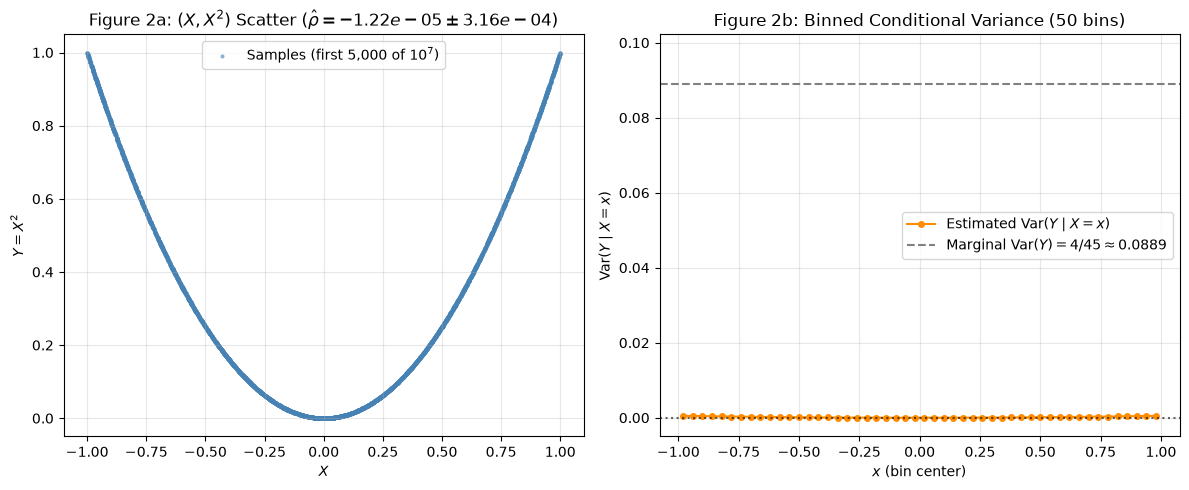

In [188]:
N2 = 10**7
X = rng_step2.uniform(-1.0, 1.0, size=N2)
Y = X**2

mean_X = np.mean(X)
mean_Y = np.mean(Y)
var_X = np.var(X, ddof=1)
var_Y = np.var(Y, ddof=1)
cov_XY = np.cov(X, Y, ddof=1)[0, 1]
rho_hat = np.corrcoef(X, Y)[0, 1]

se_rho = np.sqrt((1.0 - rho_hat**2) / (N2 - 2))

true_mean_Y = 1 / 3
true_var_X = 1 / 3
true_var_Y = 4 / 45
true_cov_XY = 0.0
true_rho = 0.0

print(f"Step 2 Numerical Verification (N = {N2:,})")
print("-" * 55)
print(f"E[Y]      : sample = {mean_Y:.6f}, analytic = {true_mean_Y:.6f}, diff = {abs(mean_Y - true_mean_Y):.2e}")
print(f"Var(X)    : sample = {var_X:.6f}, analytic = {true_var_X:.6f}, diff = {abs(var_X - true_var_X):.2e}")
print(f"Var(Y)    : sample = {var_Y:.6f}, analytic = {true_var_Y:.6f}, diff = {abs(var_Y - true_var_Y):.2e}")
print(f"Cov(X, Y) : sample = {cov_XY:.6e}, analytic = {true_cov_XY:.6f}")
print(f"Corr r    : sample = {rho_hat:.6e} ± {se_rho:.6e} (|r|/SE = {abs(rho_hat)/se_rho:.2f})")

num_bins = 50
bin_stds, bin_edges, _ = stats.binned_statistic(
    X, Y, statistic="std", bins=num_bins, range=(-1.0, 1.0)
)
bin_vars = bin_stds**2
bin_centers = 0.5 * (bin_edges[:-1] + bin_edges[1:])
max_cond_var = np.max(bin_vars)
print(f"\nMax binned Var(Y | X=x) across {num_bins} bins: {max_cond_var:.6e} (vs. marginal Var(Y) = {true_var_Y:.6f})")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

n_plot = 5000
axes[0].scatter(X[:n_plot], Y[:n_plot], s=4, alpha=0.5, color="steelblue", label=f"Samples (first {n_plot:,} of $10^7$)")
axes[0].set_title(f"Figure 2a: $(X, X^2)$ Scatter ($\\hat{{\\rho}} = {rho_hat:.2e} \\pm {se_rho:.2e}$)")
axes[0].set_xlabel("$X$")
axes[0].set_ylabel("$Y = X^2$")
axes[0].grid(True, alpha=0.3)
axes[0].legend()

axes[1].plot(bin_centers, bin_vars, "o-", markersize=4, color="darkorange", label=r"Estimated $\mathrm{Var}(Y \mid X=x)$")
axes[1].axhline(true_var_Y, linestyle="--", color="gray", label=rf"Marginal $\mathrm{{Var}}(Y) = 4/45 \approx {true_var_Y:.4f}$")
axes[1].axhline(0.0, linestyle=":", color="black", alpha=0.6)
axes[1].set_title(f"Figure 2b: Binned Conditional Variance ({num_bins} bins)")
axes[1].set_xlabel("$x$ (bin center)")
axes[1].set_ylabel(r"$\mathrm{Var}(Y \mid X=x)$")
axes[1].set_ylim(-0.005, true_var_Y * 1.15)
axes[1].grid(True, alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()

### Figure 2 Interpretation

Figure 2a shows that all simulated pairs $(X, Y)$ lie strictly on the deterministic parabola $Y = X^2$, yet the sample correlation is indistinguishable from zero within a couple of standard errors ($\approx 3.16 \times 10^{-4}$). Figure 2b confirms this total dependence quantitatively: across all 50 narrow bins of $X$, the estimated conditional variance $\text{Var}(Y \mid X=x)$ sits essentially at zero (orders of magnitude below the marginal variance $\text{Var}(Y) = 4/45 \approx 0.0889$), with the tiny residual value coming solely from the finite bin width $\Delta x = 0.04$.

### 2.4 What Correlation Actually Measures

The correlation coefficient measures only the strength and direction of a **linear** relationship between two random variables, so it is completely blind to symmetric nonlinear relationships like $Y = X^2$ where the positive slope for $X > 0$ and the negative slope for $X < 0$ cancel out exactly.

In [189]:
N_gauss = 10**6
mu = np.array([0.0, 0.0])
Sigma = np.array([[1.0, 0.0], [0.0, 1.0]])  # rho = 0

samples_g = rng_step2.multivariate_normal(mu, Sigma, size=N_gauss)
Xg, Yg = samples_g[:, 0], samples_g[:, 1]

grid_range = [-3.0, 3.0]
n_bins_g = 40

joint_hist, x_edges, y_edges = np.histogram2d(
    Xg, Yg, bins=n_bins_g, range=[grid_range, grid_range], density=True
)
marg_x, _ = np.histogram(Xg, bins=x_edges, density=True)
marg_y, _ = np.histogram(Yg, bins=y_edges, density=True)

prod_marginals = np.outer(marg_x, marg_y)

dx = x_edges[1] - x_edges[0]
dy = y_edges[1] - y_edges[0]
diff = np.abs(joint_hist - prod_marginals)

max_abs_diff = np.max(diff)
rmse = np.sqrt(np.mean(diff**2))
tv_dist = 0.5 * np.sum(diff) * dx * dy  # Total variation distance on the grid

r_gauss = np.corrcoef(Xg, Yg)[0, 1]
se_r_gauss = np.sqrt((1.0 - r_gauss**2) / (N_gauss - 2))

print(f"Jointly Gaussian Pair (rho = 0, N = {N_gauss:,})")
print("-" * 55)
print(f"Sample correlation r        : {r_gauss:.6e} ± {se_r_gauss:.6e}")
print(f"Max |f_hat(x,y) - f_x*f_y|  : {max_abs_diff:.6f}")
print(f"RMSE                        : {rmse:.6f}")
print(f"Total Variation Distance    : {tv_dist:.6f}")

Jointly Gaussian Pair (rho = 0, N = 1,000,000)
-------------------------------------------------------
Sample correlation r        : -3.811110e-04 ± 1.000001e-03
Max |f_hat(x,y) - f_x*f_y|  : 0.006659
RMSE                        : 0.001035
Total Variation Distance    : 0.011818


### 2.6 Why "Uncorrelated $\implies$ Independent" Holds for Jointly Gaussian Vectors

A jointly Gaussian distribution is completely determined by its mean vector $\mu$ and covariance matrix $\Sigma$, so when the off-diagonal covariance entries are zero ($\rho = 0$), $\Sigma$ is diagonal and the joint density factors algebraically into the product of its marginal densities, guaranteeing independence. For general non-Gaussian distributions, higher-order moments and nonlinear dependencies are not captured by $\Sigma$, so zero correlation does not imply factorization. In engineering practice, this makes the Gaussian assumption load-bearing: systems like radar processors, Kalman filters, and communications receivers rely on decorrelation (such as whitening) to treat channels as independent, which can fail badly if the underlying noise or signals are non-Gaussian.

## Step 3: The covariance matrix and its estimation

The covariance matrix in the problem is

$$\Sigma=\begin{bmatrix}4&2&1&0\\2&5&2&1\\1&2&3&1\\0&1&1&2\end{bmatrix}.$$

A covariance matrix must be symmetric and positive semidefinite. We can check this with its eigenvalues, allowing a small tolerance for rounding errors. The code also tests a non-symmetric matrix and a matrix with a negative eigenvalue.


In [190]:
Sigma4 = np.array([[4, 2, 1, 0],
                   [2, 5, 2, 1],
                   [1, 2, 3, 1],
                   [0, 1, 1, 2]], dtype=float)

non_symmetric = np.array([[1, 2], [0, 1]], dtype=float)
negative_eigenvalue = np.diag([1.0, -0.5])
eigs = np.linalg.eigvalsh(Sigma4)
det = np.linalg.det(Sigma4)

print("Sigma4 =\n", Sigma4)
print("Symmetric:", np.allclose(Sigma4, Sigma4.T))
print("Eigenvalues:", eigs)
print(f"Determinant: {det:.10f}")
print("Valid Sigma4:", is_valid_covariance(Sigma4))
print("Valid nonsymmetric matrix:", is_valid_covariance(non_symmetric))
print("Valid symmetric matrix with negative eigenvalue:", is_valid_covariance(negative_eigenvalue))

assert is_valid_covariance(Sigma4)
assert not is_valid_covariance(non_symmetric)
assert not is_valid_covariance(negative_eigenvalue)
assert np.isclose(det, 55.0)

Sigma4 =
 [[4. 2. 1. 0.]
 [2. 5. 2. 1.]
 [1. 2. 3. 1.]
 [0. 1. 1. 2.]]
Symmetric: True
Eigenvalues: [1.26487889 1.78819531 3.09808432 7.84884147]
Determinant: 55.0000000000
Valid Sigma4: True
Valid nonsymmetric matrix: False
Valid symmetric matrix with negative eigenvalue: False


### 3.1 Estimating the covariance matrix

For $N$ samples, the sample covariance is

$$\widehat\Sigma=\frac{1}{N-1}\sum_{i=1}^N(x_i-\bar x)(x_i-\bar x)^T.$$

For each $N=10^2,10^3,10^4,10^5,10^6$, we calculate $\|\widehat\Sigma-\Sigma\|_F$. The experiment first uses a single sample at each size, then repeats it the required number of times to get an average error. The standard error of that average is $s/\sqrt R$, where $R$ is the number of repeats.

The expected error rate is $1/\sqrt N$, so $\sqrt N$ times the average error should stay around the same value.


In [191]:
sample_sizes = [100, 1_000, 10_000, 100_000, 1_000_000]
repetitions = [200, 200, 100, 30, 10]

single_draw_errors = []
mean_errors = []
error_se = []

for N, repeats in zip(sample_sizes, repetitions):
    single = rng_step3.multivariate_normal(np.zeros(4), Sigma4, size=N, method="cholesky")
    _, single_cov = sample_mean_cov(single)
    single_draw_errors.append(np.linalg.norm(single_cov-Sigma4, ord="fro"))
    del single

    errors = []
    for _ in range(repeats):
        samples = rng_step3.multivariate_normal(np.zeros(4), Sigma4, size=N, method="cholesky")
        sample_mean, sample_cov = sample_mean_cov(samples)
        errors.append(np.linalg.norm(sample_cov-Sigma4, ord="fro"))
        del samples
    errors = np.array(errors)
    mean_errors.append(errors.mean())
    error_se.append(errors.std(ddof=1)/np.sqrt(repeats))

sample_sizes = np.array(sample_sizes)
mean_errors = np.array(mean_errors)
error_se = np.array(error_se)
single_draw_errors = np.array(single_draw_errors)
slope, intercept = np.polyfit(np.log10(sample_sizes), np.log10(mean_errors), 1)

cov_table = pd.DataFrame({
    "N": sample_sizes,
    "repeats": repetitions,
    "single error": single_draw_errors,
    "average error": mean_errors,
    "SE": error_se,
    "sqrt(N) * error": np.sqrt(sample_sizes)*mean_errors,
})
print(cov_table.to_string(index=False, float_format=lambda v: f"{v:.6f}"))
print(f"Fitted slope = {slope:.5f}; expected slope = -0.50000; difference = {abs(slope+0.5):.5f}")
print(f"Average scaled error sqrt(N)*error = {np.mean(np.sqrt(sample_sizes)*mean_errors):.5f}")


      N  repeats  single error  average error       SE  sqrt(N) * error
    100      200      1.427317       1.592209 0.039453        15.922092
   1000      200      0.384573       0.483418 0.010437        15.287023
  10000      100      0.178944       0.163210 0.005101        16.321028
 100000       30      0.092031       0.053811 0.003313        17.016538
1000000       10      0.026264       0.016680 0.002145        16.679743
Fitted slope = -0.49131; expected slope = -0.50000; difference = 0.00869
Average scaled error sqrt(N)*error = 16.24528


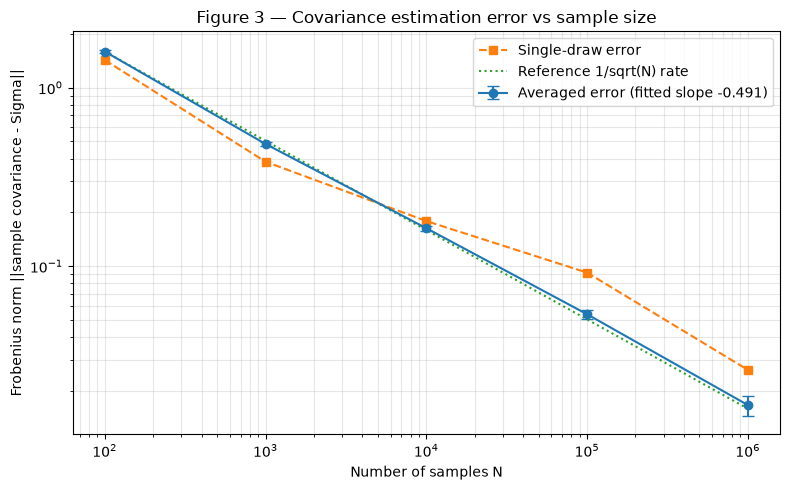

In [192]:
plt.figure(figsize=(8, 5))
plt.errorbar(sample_sizes, mean_errors, yerr=error_se, marker="o", capsize=4,
             label=f"Averaged error (fitted slope {slope:.3f})")
plt.plot(sample_sizes, single_draw_errors, "s--", label="Single-draw error")
plt.plot(sample_sizes, mean_errors[0]*np.sqrt(sample_sizes[0]/sample_sizes), ":",
         label="Reference 1/sqrt(N) rate")
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Number of samples N")
plt.ylabel("Frobenius norm ||sample covariance - Sigma||")
plt.title("Figure 3 — Covariance estimation error vs sample size")
plt.legend()
plt.grid(True, which="both", alpha=0.3)
plt.tight_layout()
plt.show()

**Figure 3.** The average error gets smaller as the sample size increases. The fitted slope is close to $-0.5$, which matches the $1/\sqrt N$ rate. The single-draw results jump around more, so they are not as reliable for fitting the slope.

### 3.2 Number of parameters and the radar example

A symmetric $d\times d$ covariance matrix has $d(d+1)/2$ different entries. That gives $10$ parameters for $d=4$ and $5050$ for $d=100$. If we roughly scale the sample count by the number of parameters, the estimate is

$$10^4\times\frac{5050}{10}=5.05\times10^6\text{ samples}.$$

This is only a rough estimate; the actual relative error also depends on the covariance matrix.

A radar with 100 array elements has to estimate thousands of covariance entries, so having too few samples can make the estimates noisy and hurt detection. One way to handle this is to use covariance shrinkage, which makes the estimate more stable.


In [193]:
print("Free covariance parameters with d=4:", 4*(4+1)//2)
print("Free covariance parameters with d=100:", 100*(100+1)//2)
print(f"Parameter-count sample heuristic: {10_000*(5050/10):,.0f} samples")

Free covariance parameters with d=4: 10
Free covariance parameters with d=100: 5050
Parameter-count sample heuristic: 5,050,000 samples


# Step 4: Linear Transformations of Random Vectors

**4.1 Linear Transformation Rules**

The mean of the linear transformation $y=Ax+b$ is $A\mu_x+b$ and its covariance is $A\Sigma_x A^T$. In this derivation, the mean is transformed by the matrix A and vector b, while the covariance is transformed only by matrix A.

The derivation of the transformation mean is:
$$
\begin{align}
\mu_y &= E[y] \\
&= E[Ax+b] \\
&= AE[x]+b \\
&= A\mu_x+b
\end{align}
$$

The derivation of the transformation covariance is:
$$
\begin{align}
\Sigma_y &= E[(y-\mu_y)(y-\mu_y)^T] \\
&= E[(Ax+b-A\mu_x-b)(Ax+b-A\mu_x-b)^T] \\
&= E[A(x-\mu_x)(x-\mu_x)^T A^T] \\
&= A\Sigma_x A^T
\end{align}
$$


**4.2 Calculating Mean and Covariance**

Given:

$$
\mu_x = \begin{bmatrix} 1\\-2 \end{bmatrix},
\quad
\Sigma_x = \begin{bmatrix} 4&2\\2&4 \end{bmatrix},
\quad
A = \begin{bmatrix} 1&2\\0&1\\1&-1 \end{bmatrix}
$$

Since $\mu_y = A\mu_x$, $\mu_y$ is calculated by:
$$
\begin{align}
\mu_y &= A\mu_x \\
&= \begin{bmatrix} 1&2\\0&1\\1&-1 \end{bmatrix}
\begin{bmatrix} 1\\-2 \end{bmatrix} \\
&= \begin{bmatrix} -3\\-2\\3 \end{bmatrix}
\end{align}
$$

Since $\Sigma_y = A\Sigma_x A^T$, $\Sigma_y$ can also be computed using the given matrices:

$$
\begin{align}
\Sigma_y &= A\Sigma_x A^T \\
&= \begin{bmatrix}1&2\\0&1\\1&-1\end{bmatrix}
\begin{bmatrix}4&2\\2&4\end{bmatrix}
\begin{bmatrix}1&0&1\\2&1&-1\end{bmatrix} \\
&= \begin{bmatrix}8&10\\2&4\\2&-2\end{bmatrix}
\begin{bmatrix}1&0&1\\2&1&-1\end{bmatrix} \\
&= \begin{bmatrix}
28&10&-2\\
10&4&-2\\
-2&-2&4
\end{bmatrix}
\end{align}
$$

**4.3 Computation Explanation**

The rank of $\Sigma_y$ is 2 because the linear transformation of the two input variables results in three output variables, indicating that the transformation results in two linearly independent rows. Geometrically, this indicates that the output samples exist on a two dimensional plane in the 3D space.

**4.4 Rank Deficient Calculation**

The mean of the rank-deficient transformation is calculated as follows:

$$
\begin{align}
\mu_y &= A\mu_x \\
&=\begin{bmatrix} 1&1\\2&2 \end{bmatrix}
\begin{bmatrix} 1\\-2 \end{bmatrix}\\
&=\begin{bmatrix} -1\\-2 \end{bmatrix}
\end{align}
$$

The covariance of this transformation can be calculated by:

$$
\begin{aligned}
\Sigma_y &= A\Sigma_x A^T\\
&=\begin{bmatrix}1&1\\2&2\end{bmatrix}
\begin{bmatrix}4&2\\2&4\end{bmatrix}
\begin{bmatrix}1&2\\1&2\end{bmatrix}\\
&=\begin{bmatrix}6&6\\12&12\end{bmatrix}
\begin{bmatrix}1&2\\1&2\end{bmatrix}\\
&=\begin{bmatrix}12&24\\24&48\end{bmatrix}
\end{aligned}
$$

The rank of $\Sigma_y$ is 1 because only one row of the linear transformation is linearly independent. The transoformation calculation shows that the second row of the resulting matrix is twice its first row values. The geometric interpretation of this rank deficiency indicates that the output samples exist on a single line.


In [194]:
covariance = np.array([[12, 24], [24, 48]])
determinant = np.linalg.det(covariance)
print("Determinant:", determinant)

if np.isclose(determinant, 0):
    print("The covariance determinant is 0.")
else:
    print("The covariance determinant is non-zero.")


Determinant: 0.0
The covariance determinant is 0.


**Density Formula Conclusion**

The density formula cannot be evaluated because the determinant of the covariance matrix is approximately 0, meaning that the covariance matrix is singular. As a result, its inverse does not exist because the matrix is non-invertible.

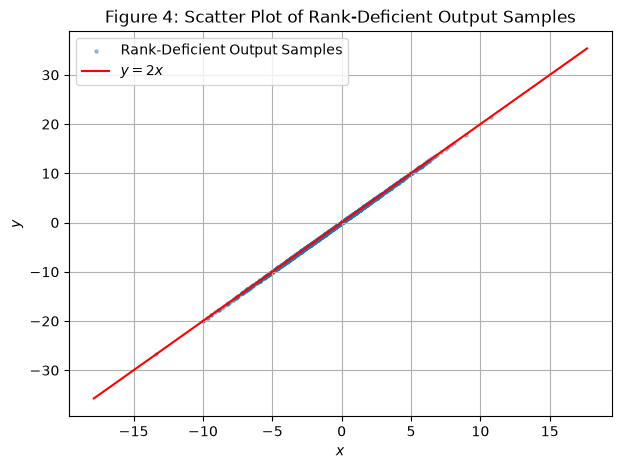

In [195]:
mean_samples = np.array([1, -2])
covariance_samples = np.array([[4, 2], [2, 4]])

samples_matrix = rng_step4.multivariate_normal(mean_samples, covariance_samples, size=10**6)

rank_def_A = np.array([[1, 1], [2, 2]])
transformed_A = np.dot(samples_matrix, rank_def_A.T)

plt.figure(figsize=(7, 5))
plt.scatter(transformed_A[:1000, 0], transformed_A[:1000, 1], s=5, alpha=0.4, label="Rank-Deficient Output Samples")

x_line = np.linspace(transformed_A[:, 0].min(), transformed_A[:, 0].max(), 100)
plt.plot(x_line, 2*x_line, 'r-', label=r"$y=2x$")

plt.xlabel(r"$x$")
plt.ylabel(r"$y$")
plt.title("Figure 4: Scatter Plot of Rank-Deficient Output Samples")
plt.legend()
plt.grid(True)
plt.show()

**Figure 4 Interpretation**

In Figure 4, the transformed output samples lie on the line $y_2=2y_1$. This indicates that the output samples exist on a singular dimension line in a 2D space. The rank of the covariance matrix is 1, where there exists one linearly independent row in the matrix.

# Step 5: The Multivariate Gaussian

For a $d$-dimensional random vector $x \in \mathbb{R}^d$, the multivariate Gaussian probability density function is:

$$f(x) = \frac{1}{(2\pi)^{d/2} |\Sigma|^{1/2}} \exp\left(-\frac{1}{2}(x - \mu)^T \Sigma^{-1} (x - \mu)\right)$$

where:
- $d$ is the dimension of the random vector,
- $x \in \mathbb{R}^d$ is the evaluation point,
- $\mu \in \mathbb{R}^d$ is the mean vector,
- $\Sigma \in \mathbb{R}^{d \times d}$ is the symmetric, positive definite covariance matrix,
- $|\Sigma| = \det(\Sigma)$ is the determinant of the covariance matrix,
- $(x - \mu)^T \Sigma^{-1} (x - \mu)$ is the squared Mahalanobis distance from $x$ to $\mu$.

Throughout this step, we use $d = 2$, $\mu = [0, 0]^T$, and:

$$\Sigma = \begin{bmatrix} 4 & 2 \\ 2 & 4 \end{bmatrix}$$

In [196]:
mu5 = np.array([0.0, 0.0])
Sigma5 = np.array([[4.0, 2.0], [2.0, 4.0]])

test_points = np.array([
    [0.0, 0.0],
    [1.5, -0.5],
    [-2.0, 3.0],
    [4.0, 4.0],
    [-3.5, -1.2]
])

pdf_ours = mp3lib.gaussian_pdf(test_points, mu5, Sigma5)
pdf_scipy = stats.multivariate_normal.pdf(test_points, mean=mu5, cov=Sigma5)
rel_diffs = np.abs(pdf_ours - pdf_scipy) / pdf_scipy
max_rel_diff = np.max(rel_diffs)

print("Verification against scipy.stats.multivariate_normal.pdf:")
for pt, p1, p2, rd in zip(test_points, pdf_ours, pdf_scipy, rel_diffs):
    print(f"  x = {pt} -> ours = {p1:.8e}, scipy = {p2:.8e}, rel diff = {rd:.2e}")
print(f"Largest relative difference: {max_rel_diff:.2e}\n")


grid_limit = 12.0
n_grid = 400
x_lin = np.linspace(-grid_limit, grid_limit, n_grid)
y_lin = np.linspace(-grid_limit, grid_limit, n_grid)
dx = x_lin[1] - x_lin[0]
dy = y_lin[1] - y_lin[0]

XX, YY = np.meshgrid(x_lin, y_lin)
grid_pts = np.stack([XX, YY], axis=-1)
Z = mp3lib.gaussian_pdf(grid_pts, mu5, Sigma5)

integral_val = np.sum(Z) * dx * dy
print(f"Numerical integral over [-{grid_limit}, {grid_limit}]^2: {integral_val:.10f}")
print(f"Difference from 1.0: {abs(integral_val - 1.0):.2e}")

Verification against scipy.stats.multivariate_normal.pdf:
  x = [0. 0.] -> ours = 4.59440746e-02, scipy = 4.59440746e-02, rel diff = 1.51e-16
  x = [ 1.5 -0.5] -> ours = 2.67292433e-02, scipy = 2.67292433e-02, rel diff = 2.60e-16
  x = [-2.  3.] -> ours = 1.93625989e-03, scipy = 1.93625989e-03, rel diff = 6.72e-16
  x = [4. 4.] -> ours = 3.19235287e-03, scipy = 3.19235287e-03, rel diff = 1.09e-15
  x = [-3.5 -1.2] -> ours = 9.44757619e-03, scipy = 9.44757619e-03, rel diff = 7.34e-16
Largest relative difference: 1.09e-15

Numerical integral over [-12.0, 12.0]^2: 0.9999999964
Difference from 1.0: 3.59e-09


Contour levels and empirical enclosed fractions (N = 10,000):
  50% contour: r^2 = 1.3863, pdf level = 0.022972, empirical = 0.4998 (diff = 0.0002, SE = 0.0050)
  90% contour: r^2 = 4.6052, pdf level = 0.004594, empirical = 0.9019 (diff = 0.0019, SE = 0.0030)
  99% contour: r^2 = 9.2103, pdf level = 0.000459, empirical = 0.9915 (diff = 0.0015, SE = 0.0010)

rho = 0.5000, det(Sigma) = 12.0000
Axis 1: eigenvalue = 2.0000, 1-sigma semi-axis = 1.4142, direction = [-0.70710678  0.70710678] (135.0 deg)
Axis 2: eigenvalue = 6.0000, 1-sigma semi-axis = 2.4495, direction = [0.70710678 0.70710678] (45.0 deg)


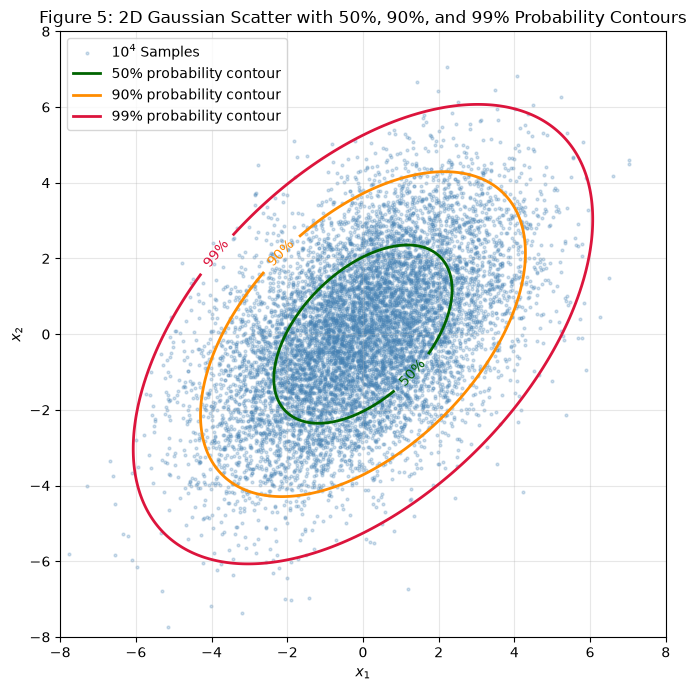

In [197]:
N5 = 10**4
samples5 = rng_step5.multivariate_normal(mu5, Sigma5, size=N5)

probs = [0.50, 0.90, 0.99]

maha_sq_levels = [-2.0 * np.log(1.0 - p) for p in probs]

det5 = np.linalg.det(Sigma5)
norm_const5 = 1.0 / (2.0 * np.pi * np.sqrt(det5))
pdf_levels = [norm_const5 * np.exp(-0.5 * c) for c in maha_sq_levels]

diff_samples = samples5 - mu5
solved_samples = np.linalg.solve(Sigma5, diff_samples.T)
sample_maha_sq = np.sum(diff_samples.T * solved_samples, axis=0)

print("Contour levels and empirical enclosed fractions (N = 10,000):")
for p, c, lvl in zip(probs, maha_sq_levels, pdf_levels):
    emp_frac = np.mean(sample_maha_sq <= c)
    se = np.sqrt(p * (1.0 - p) / N5)
    print(f"  {int(p*100)}% contour: r^2 = {c:.4f}, pdf level = {lvl:.6f}, "
          f"empirical = {emp_frac:.4f} (diff = {abs(emp_frac - p):.4f}, SE = {se:.4f})")

rho5 = Sigma5[0, 1] / np.sqrt(Sigma5[0, 0] * Sigma5[1, 1])
eigvals5, eigvecs5 = np.linalg.eigh(Sigma5)

print(f"\nrho = {rho5:.4f}, det(Sigma) = {det5:.4f}")
for i in range(2):
    angle_deg = np.degrees(np.arctan2(eigvecs5[1, i], eigvecs5[0, i]))
    print(f"Axis {i+1}: eigenvalue = {eigvals5[i]:.4f}, "
          f"1-sigma semi-axis = {np.sqrt(eigvals5[i]):.4f}, "
          f"direction = {eigvecs5[:, i]} ({angle_deg:.1f} deg)")

x_plot = np.linspace(-8, 8, 300)
y_plot = np.linspace(-8, 8, 300)
Xp, Yp = np.meshgrid(x_plot, y_plot)
Zp = mp3lib.gaussian_pdf(np.stack([Xp, Yp], axis=-1), mu5, Sigma5)

fig, ax = plt.subplots(figsize=(7, 7))
ax.scatter(samples5[:, 0], samples5[:, 1], s=4, alpha=0.25, color="steelblue", label="$10^4$ Samples")

levels_sorted = pdf_levels[::-1]
labels_sorted = ["99%", "90%", "50%"]
colors_sorted = ["crimson", "darkorange", "darkgreen"]

cs = ax.contour(Xp, Yp, Zp, levels=levels_sorted, colors=colors_sorted, linewidths=2)
fmt = {lvl: lbl for lvl, lbl in zip(levels_sorted, labels_sorted)}
ax.clabel(cs, fmt=fmt, inline=True, fontsize=10)

for lbl, col in zip(labels_sorted[::-1], colors_sorted[::-1]):
    ax.plot([], [], color=col, linewidth=2, label=f"{lbl} probability contour")

ax.set_aspect("equal")
ax.set_xlim(-8, 8)
ax.set_ylim(-8, 8)
ax.set_xlabel("$x_1$")
ax.set_ylabel("$x_2$")
ax.set_title("Figure 5: 2D Gaussian Scatter with 50%, 90%, and 99% Probability Contours")
ax.grid(True, alpha=0.3)
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

### Figure 5 Interpretation

To find the contour levels enclosing probability $p$, we use the fact that for a 2D Gaussian the squared Mahalanobis distance $r^2 = (x - \mu)^T \Sigma^{-1} (x - \mu)$ follows a $\chi^2_2$ distribution, which gives $r^2 = -2\ln(1 - p)$ (1.3863 for 50%, 4.6052 for 90%, and 9.2103 for 99%) and corresponding density levels $f = \frac{1}{2\pi\sqrt{|\Sigma|}} e^{-r^2/2}$. The empirical sample fractions inside each ellipse match the theoretical targets within sampling error.

Because $\rho = 0.5$ and $\Sigma$ is symmetric with equal diagonal entries, the probability contours are ellipses tilted at $+45^\circ$ (major axis along $[1, 1]^T/\sqrt{2}$ with $1\sigma$ semi-axis length $\sqrt{6} \approx 2.4495$) and $-45^\circ$ (minor axis along $[1, -1]^T/\sqrt{2}$ with $1\sigma$ semi-axis length $\sqrt{2} \approx 1.4142$).

Correlation sweep (variances fixed at 4):
  rho = 0.00 -> det(Sigma) = 16.0000
  rho = 0.50 -> det(Sigma) = 12.0000
  rho = 0.90 -> det(Sigma) = 3.0400
  rho = 0.99 -> det(Sigma) = 0.3184


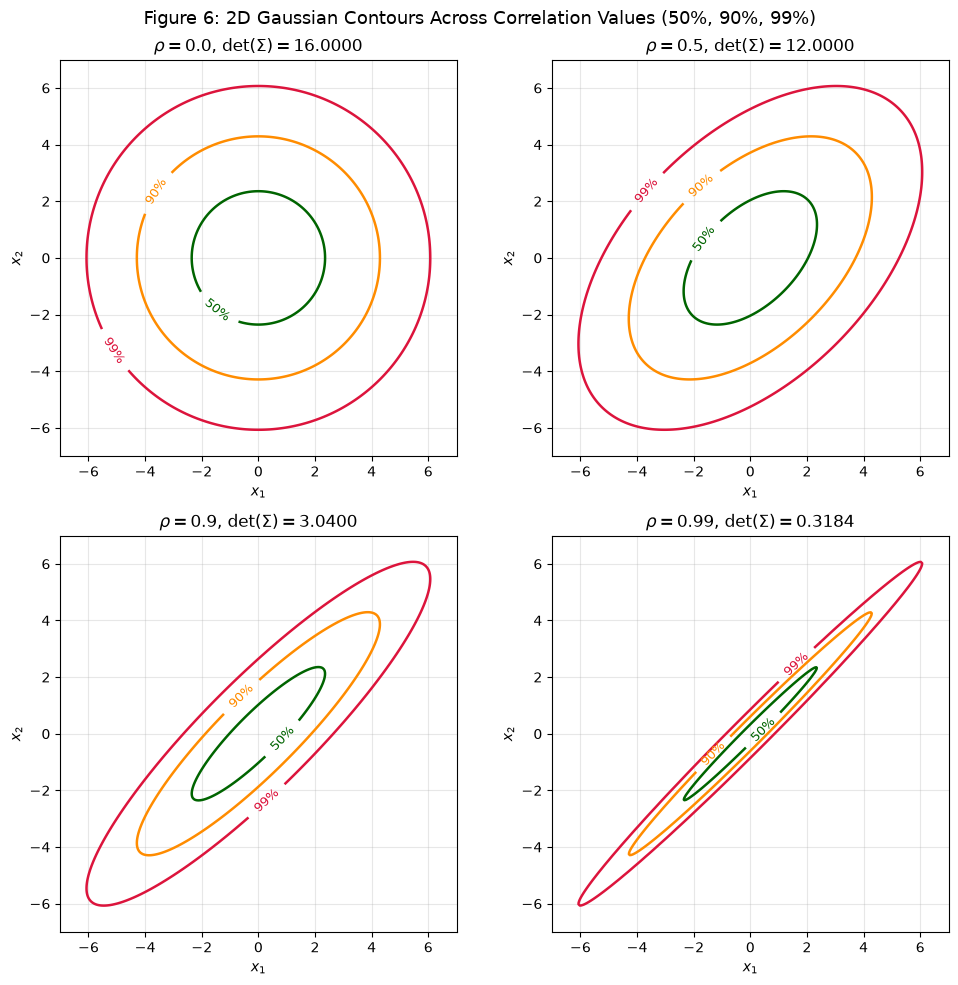

In [198]:
rhos = [0.0, 0.5, 0.9, 0.99]
var_fixed = 4.0

fig, axes = plt.subplots(2, 2, figsize=(10, 10))
axes = axes.ravel()

print("Correlation sweep (variances fixed at 4):")
for ax, rho in zip(axes, rhos):
    cov_val = rho * var_fixed
    Sig = np.array([[var_fixed, cov_val], [cov_val, var_fixed]])
    det_s = np.linalg.det(Sig)
    print(f"  rho = {rho:4.2f} -> det(Sigma) = {det_s:.4f}")

    norm_c = 1.0 / (2.0 * np.pi * np.sqrt(det_s))
    lvls = [norm_c * np.exp(-0.5 * c) for c in maha_sq_levels][::-1]

    Z_sweep = mp3lib.gaussian_pdf(np.stack([Xp, Yp], axis=-1), mu5, Sig)
    cs = ax.contour(Xp, Yp, Z_sweep, levels=lvls, colors=colors_sorted, linewidths=1.8)
    ax.clabel(cs, fmt={l: s for l, s in zip(lvls, labels_sorted)}, inline=True, fontsize=9)

    ax.set_aspect("equal")
    ax.set_xlim(-7, 7)
    ax.set_ylim(-7, 7)
    ax.set_xlabel("$x_1$")
    ax.set_ylabel("$x_2$")
    ax.set_title(f"$\\rho = {rho}$, $\\det(\\Sigma) = {det_s:.4f}$")
    ax.grid(True, alpha=0.3)

fig.suptitle("Figure 6: 2D Gaussian Contours Across Correlation Values (50%, 90%, 99%)", fontsize=13)
plt.tight_layout()
plt.show()

### Figure 6 Interpretation

At $\rho = 0$, the contours are perfect circles because the two variables are independent with equal variance. As $\rho \to 1$, the ellipses stretch along the $x_1 = x_2$ diagonal and collapse tightly along the perpendicular direction, while $\det(\Sigma) = 16(1 - \rho^2)$ shrinks toward zero (dropping from $16$ at $\rho = 0$ down to $0.3184$ at $\rho = 0.99$). In terms of information content, a correlation near $1$ means the second measurement is almost completely redundant with the first, so it adds very little new independent information.


# Step 6: Eigendecomposition, Decorrelation, and Whitening

For this step, we use the same zero-mean Gaussian setup from Step 5 with:

$$
\Sigma = \begin{bmatrix} 4 & 2 \\ 2 & 4 \end{bmatrix}
$$

Using the eigendecomposition $\Sigma = V \Lambda V^T$, we can rotate the correlated samples into uncorrelated coordinates with $y = V^T x$ and scale them to unit variance with the whitening matrix $W = \Lambda^{-1/2} V^T$.

In [199]:
Sigma6 = np.array([[4.0, 2.0], [2.0, 4.0]])
eigvals6, V6 = np.linalg.eigh(Sigma6)

print("Eigenvalues:")
print(eigvals6)
print()
print("Eigenvectors (columns of V):")
print(V6)
print()

Y_dec = samples5 @ V6
cov_Y = np.cov(Y_dec, rowvar=False)
Lambda6 = np.diag(eigvals6)
diff_dec = np.linalg.norm(cov_Y - Lambda6, ord="fro")

print("Sample covariance of decorrelated samples y = V^T x:")
print(cov_Y)
print(f"Frobenius norm ||Cov(y) - Lambda||_F = {diff_dec:.6f}")
print()

W6 = mp3lib.whitening_matrix(Sigma6)
Z_white = samples5 @ W6.T
cov_Z = np.cov(Z_white, rowvar=False)
I2 = np.eye(2)
diff_white_analytic = np.linalg.norm(W6 @ Sigma6 @ W6.T - I2, ord="fro")
diff_white_sample = np.linalg.norm(cov_Z - I2, ord="fro")

print("Whitening matrix W:")
print(W6)
print(f"Analytic ||W Sigma W^T - I||_F = {diff_white_analytic:.2e}")
print("Sample covariance of whitened samples Wx:")
print(cov_Z)
print(f"Sample ||Cov(Wx) - I||_F = {diff_white_sample:.6f}")

Eigenvalues:
[2. 6.]

Eigenvectors (columns of V):
[[-0.70710678  0.70710678]
 [ 0.70710678  0.70710678]]

Sample covariance of decorrelated samples y = V^T x:
[[ 1.99414836 -0.00886347]
 [-0.00886347  5.94732624]]
Frobenius norm ||Cov(y) - Lambda||_F = 0.054460

Whitening matrix W:
[[-0.5         0.5       ]
 [ 0.28867513  0.28867513]]
Analytic ||W Sigma W^T - I||_F = 4.97e-16
Sample covariance of whitened samples Wx:
[[ 0.99707418 -0.00255866]
 [-0.00255866  0.99122104]]
Sample ||Cov(Wx) - I||_F = 0.009936


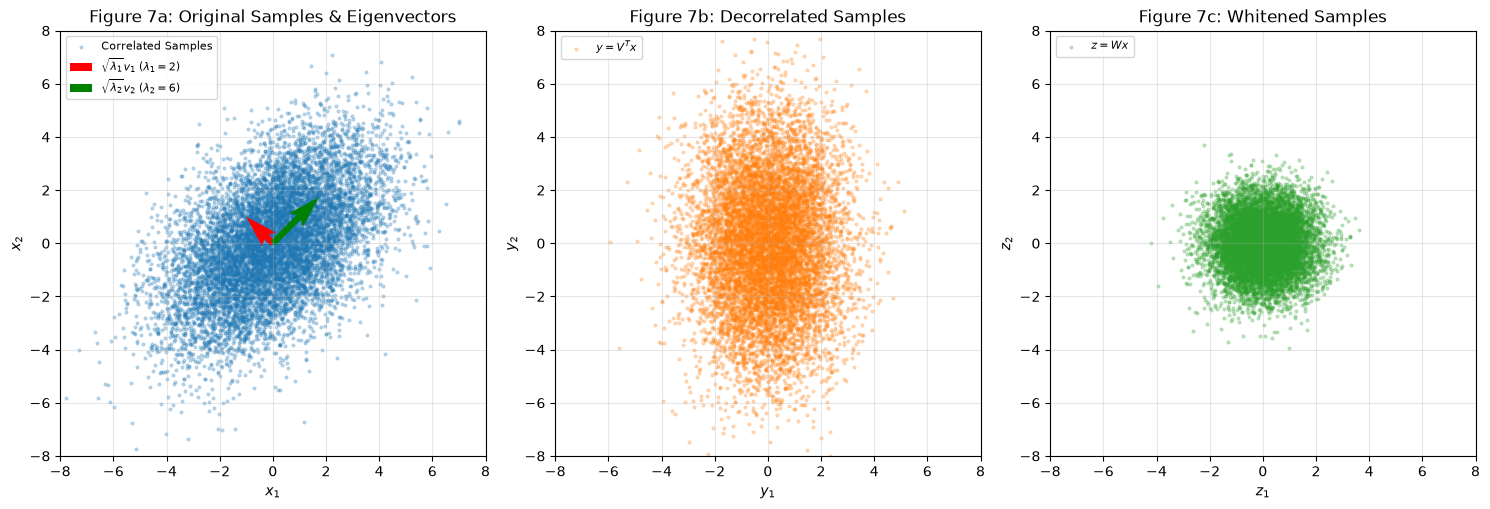

In [200]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(15, 5))

ax1.scatter(samples5[:, 0], samples5[:, 1], s=4, alpha=0.25, label="Correlated Samples")
v1 = np.sqrt(eigvals6[0]) * V6[:, 0]
v2 = np.sqrt(eigvals6[1]) * V6[:, 1]
ax1.quiver(0, 0, v1[0], v1[1], angles="xy", scale_units="xy", scale=1, color="red", width=0.015, label=rf"$\sqrt{{\lambda_1}} v_1$ ($\lambda_1={eigvals6[0]:.0f}$)")
ax1.quiver(0, 0, v2[0], v2[1], angles="xy", scale_units="xy", scale=1, color="green", width=0.015, label=rf"$\sqrt{{\lambda_2}} v_2$ ($\lambda_2={eigvals6[1]:.0f}$)")
ax1.set_title("Figure 7a: Original Samples & Eigenvectors")
ax1.set_xlabel("$x_1$")
ax1.set_ylabel("$x_2$")
ax1.legend(loc="upper left", fontsize=8)

ax2.scatter(Y_dec[:, 0], Y_dec[:, 1], s=4, alpha=0.25, color="tab:orange", label="$y = V^T x$")
ax2.set_title("Figure 7b: Decorrelated Samples")
ax2.set_xlabel("$y_1$")
ax2.set_ylabel("$y_2$")
ax2.legend(loc="upper left", fontsize=8)

ax3.scatter(Z_white[:, 0], Z_white[:, 1], s=4, alpha=0.25, color="tab:green", label="$z = W x$")
ax3.set_title("Figure 7c: Whitened Samples")
ax3.set_xlabel("$z_1$")
ax3.set_ylabel("$z_2$")
ax3.legend(loc="upper left", fontsize=8)

for ax in (ax1, ax2, ax3):
    ax.set_aspect("equal")
    ax.set_xlim(-8, 8)
    ax.set_ylim(-8, 8)
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### Figure 7 interpretation

The eigenvalues from eigh are $2$ and $6$, and the eigenvectors lie at $\pm 45^\circ$. In Figure 7a, the scaled eigenvectors $\sqrt{2}\,v_1$ and $\sqrt{6}\,v_2$ align directly with the short and long axes of the ellipse. In Figure 7b, applying $y = V^T x$ rotates the ellipse so its axes line up with the coordinate axes, making the sample covariance diagonal with entries close to $2$ and $6$. In Figure 7c, applying $W = \Lambda^{-1/2} V^T$ scales both axes to unit variance, turning the ellipse into a circular cloud whose sample covariance is close to the identity matrix $I$.

In [201]:
theta = np.deg2rad(35.0)
Q = np.array([
    [np.cos(theta), -np.sin(theta)],
    [np.sin(theta),  np.cos(theta)]
])

W_rot = Q @ W6
Z_rot = samples5 @ W_rot.T
cov_Z_rot = np.cov(Z_rot, rowvar=False)

diff_rot_analytic = np.linalg.norm(W_rot @ Sigma6 @ W_rot.T - I2, ord="fro")
diff_rot_sample = np.linalg.norm(cov_Z_rot - I2, ord="fro")

print("Rotated whitening matrix QW (35 degrees):")
print(f"Analytic ||(QW) Sigma (QW)^T - I||_F = {diff_rot_analytic:.2e}")
print(f"Sample   ||Cov(QWx) - I||_F          = {diff_rot_sample:.6f}")
print()

Sigma4 = np.array([
    [4.0, 2.0, 1.0, 0.0],
    [2.0, 5.0, 2.0, 1.0],
    [1.0, 2.0, 3.0, 1.0],
    [0.0, 1.0, 1.0, 2.0]
])

W4 = mp3lib.whitening_matrix(Sigma4)
I4 = np.eye(4)
diff_4d_analytic = np.linalg.norm(W4 @ Sigma4 @ W4.T - I4, ord="fro")

N6_4d = 10**6
X4 = rng_step6.multivariate_normal(np.zeros(4), Sigma4, size=N6_4d)
Z4 = X4 @ W4.T
cov_Z4 = np.cov(Z4, rowvar=False)
diff_4d_sample = np.linalg.norm(cov_Z4 - I4, ord="fro")

print(f"4D whitening check (N = {N6_4d:,}):")
print(f"Analytic ||W4 Sigma4 W4^T - I4||_F = {diff_4d_analytic:.2e}")
print("Sample covariance of W4 x:")
print(np.round(cov_Z4, 5))
print(f"Sample   ||Cov(W4 x) - I4||_F      = {diff_4d_sample:.6f}")

Rotated whitening matrix QW (35 degrees):
Analytic ||(QW) Sigma (QW)^T - I||_F = 6.56e-16
Sample   ||Cov(QWx) - I||_F          = 0.009936

4D whitening check (N = 1,000,000):
Analytic ||W4 Sigma4 W4^T - I4||_F = 8.05e-16
Sample covariance of W4 x:
[[ 9.98520e-01 -1.60000e-04  3.60000e-04 -2.60000e-04]
 [-1.60000e-04  9.99100e-01 -6.60000e-04 -1.95000e-03]
 [ 3.60000e-04 -6.60000e-04  1.00218e+00 -1.48000e-03]
 [-2.60000e-04 -1.95000e-03 -1.48000e-03  1.00074e+00]]
Sample   ||Cov(W4 x) - I4||_F      = 0.004642


### Non-uniqueness and 4D whitening

In practice, the non-uniqueness of whitening means that any orthogonal rotation of whitened data still gives uncorrelated, unit-variance features, so we can choose a rotation that best fits the problem (such as keeping the principal axes or staying close to the original coordinates).

Applying whitening_matrix to the 4-dimensional covariance matrix from Step 3 also produces $W_4 \Sigma_4 W_4^T = I_4$ to machine precision, and the sample covariance of $10^6$ whitened 4D samples matches $I_4$ within estimation error.

# Step 7: The Conditional Gaussian

**7.1** For the jointly Gaussian pair $\Sigma = \begin{bmatrix} 4&2\\2&4 \end{bmatrix}$: the mean $\mu_X, \mu_Y = 0$, variance of X and Y is 4, and the covariance of X and Y is 2. The conditional density of $Y$ given $X=x$ can be derived as follows:

<u>Mean:</u>

$$
\begin{align}
E[Y \mid X=x] &= \mu_Y + \frac{\operatorname{Cov}(Y,X)}{\operatorname{Var}(X)}(x-\mu_X) \\
&= 0 + \frac{2}{4}(x-0) \\
&= 0.5x
\end{align}
$$

<u>Variance:</u>

$$
\begin{align}
\operatorname{Var}(Y \mid X=x)
&= \operatorname{Var}(Y) - \frac{\operatorname{Cov}(Y,X)^2}{\operatorname{Var}(X)} \\
&= 4-\frac{2^2}{4} \\
&= 3
\end{align}
$$

<u>Gaussian density:</u>

Since $Y$ and $X$ are jointly Gaussian, the conditional distribution of $Y$ given $X=x$ is Gaussian as well. Therefore, the conditional probability density is:

$$
\begin{align}
f(y\mid x) &= \frac{1}{\sqrt{2\pi\sigma^2}}
e^{-\frac{(y-\mu)^2}{2\sigma^2}} \\
&= \frac{1}{\sqrt{6\pi}}
e^{-\frac{(y-0.5x)^2}{6}}
\end{align}
$$


**7.2**

The general result for a partitioned Gaussian vector calculated as follows:

Given

$$
\mu_X=\mu_Y=0,\quad
\Sigma_{XX}=4,\quad
\Sigma_{YX}=\Sigma_{XY}=2,\quad
\Sigma_{YY}=4
$$

$$
\begin{bmatrix}X\\Y\end{bmatrix}
\sim N\left(
\begin{bmatrix}\mu_X\\\mu_Y\end{bmatrix},
\begin{bmatrix}
\Sigma_{XX} & \Sigma_{XY}\\
\Sigma_{YX} & \Sigma_{YY}
\end{bmatrix}
\right)
$$

The mean and covariance is calculated by:
$$
\begin{align}
E[Y\mid X=x] &=\mu_Y+\Sigma_{YX}\Sigma_{XX}^{-1}(x-\mu_X) \\
&= 0+2(4^{-1})(x-0) \\
&=0.5x
\end{align}
$$

$$
\begin{align}
\operatorname{Var}(Y\mid X=x) &= \Sigma_{YY}-\Sigma_{YX}\Sigma_{XX}^{-1}\Sigma_{XY}\\
&= 4-2(4^{-1})(2) \\
&=3
\end{align}
$$

Therefore, the conditional distribution of $Y$ given $X=x$ is $Y\mid X=x \sim N(0.5x,3)$.

Fitted Slope: 0.500234
Standard Error of the Fitted Slope: 0.001119
Theoretical Slope: 0.5


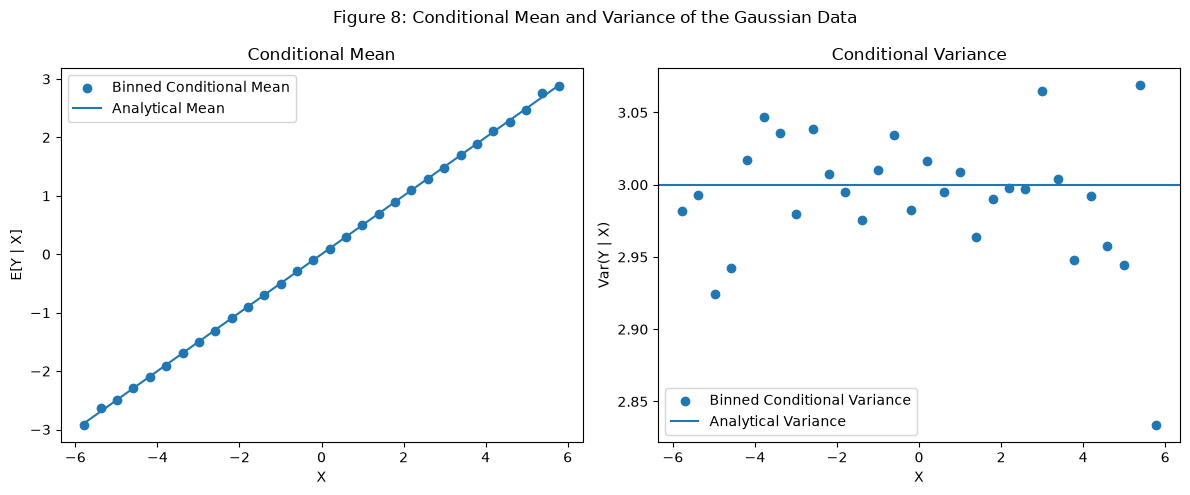

In [202]:
covariance = np.array([[4, 2],[2, 4]])
samples = rng_step7.multivariate_normal([0, 0], covariance, size=10**6)

X = samples[:, 0]
Y = samples[:, 1]

bins = np.linspace(-6, 6, 31)
bin_index = np.digitize(X, bins) - 1

x_mean = []
y_mean = []
y_var = []
counts = []

for i in range(len(bins)-1):
    valid_bins = bin_index == i

    if np.sum(valid_bins) > 1:
        x_mean.append(np.mean(X[valid_bins]))
        y_mean.append(np.mean(Y[valid_bins]))
        y_var.append(np.var(Y[valid_bins], ddof=1))
        counts.append(np.sum(valid_bins))

x_means = np.array(x_mean)
y_means = np.array(y_mean)
y_variances = np.array(y_var)
counts = np.array(counts)

fitted_slope, intercept = np.polyfit(x_means, y_means, 1)

y_predicted = fitted_slope * x_means + intercept
errors = y_means - y_predicted

fitted_std_error = np.sqrt(np.sum(errors**2) / ((len(x_means)-2) * np.sum((x_means - np.mean(x_means))**2)))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.suptitle("Figure 8: Conditional Mean and Variance of the Gaussian Data")

axes[0].scatter(x_means, y_means, label="Binned Conditional Mean")
axes[0].plot(x_means, 0.5*x_means,label="Analytical Mean")
axes[0].set_title("Conditional Mean")
axes[0].set_xlabel("X")
axes[0].set_ylabel("E[Y | X]")
axes[0].legend()

axes[1].scatter(x_means, y_variances,label="Binned Conditional Variance")
axes[1].axhline(3, label="Analytical Variance")
axes[1].set_title("Conditional Variance")
axes[1].set_xlabel("X")
axes[1].set_ylabel("Var(Y | X)")
axes[1].legend()

print(f"Fitted Slope: {fitted_slope:.6f}")
print(f"Standard Error of the Fitted Slope: {fitted_std_error:.6f}")
print(f"Theoretical Slope: 0.5")

plt.tight_layout()
plt.show()


**Figure 8 Interpretation**

In the plot of the conditional mean, the distribution of the binned mean match the linear function $E[Y\mid X=x]=0.5x$. This indicates that the conditional mean increases linearly with increasing $X$. In the plot of conditional variance, the binned conditional variance are distributed near the theoretical variance at 3. This distribution shows that the conditional variance is indepedent of changing $X$.

**5. Linearity of the Conditional Mean**

For  Gaussian data, the linearity of the conditional mean indicates that the expected value of a variable can be expressed as a linear function of other variable. The linear estimator is optimal because it can determine the lowest MSE as the conditional mean reduces the MSE.

# Step 8: Fusing Two Correlated Sensors

**8.1** Given the two sensors $X_1 = S + N_1, X_2 = S + N_2$ and noise covariance matrix $\Sigma_N = \begin{bmatrix} 1 & c\\ c & 2 \end{bmatrix}$:


$$
\operatorname{Var}(X_1) = \operatorname{Var}(S) + \operatorname{Var}(N_1) = 4+1=5
$$

$$
\operatorname{Var}(X_2) = \operatorname{Var}(S) + \operatorname{Var}(N_2) = 4+2=6
$$

$$
\operatorname{Cov}(X_1,X_2) = \operatorname{Var}(S) + \operatorname{Cov}(N_1,N_2) = 4+c
$$

The covariance matrix of $\Sigma_{xx}$ can then be determined as
$$
\Sigma_{xx} =
\begin{bmatrix}
5 & 4+c\\
4+c & 6
\end{bmatrix}
$$

The covariance between the signal and sensor is then

$$
\operatorname{Cov}(S,X_1) = \operatorname{Cov}(S,S+N_1)=4
$$

$$
\operatorname{Cov}(S,X_2) = \operatorname{Cov}(S,S+N_2)=4
$$

The covariance matrix of $\Sigma_{sx}$ can then be determined as

$$
{\Sigma_{sx} = \begin{bmatrix}4&4\end{bmatrix}}
$$

**8.2**

Given $\hat{S} = \mathbf{w}^T\mathbf{x}$ and $\mathbf{w} = \Sigma_{xx}^{-1}\Sigma_{sx}^T$,

$$
\mathbf{w} =
\begin{bmatrix}
5 & 4+c\\
4+c & 6
\end{bmatrix}^{-1}
\begin{bmatrix}
4\\
4
\end{bmatrix}
$$

The determinant of $\Sigma_{xx}$ is:

$$
D = 30-(4+c)^2 = 14-8c-c^2
$$

The inverse matrix is determined by:

$$
\mathbf{w} =
\frac{1}{D}
\begin{bmatrix}
6 & -(4+c)\\
-(4+c) & 5
\end{bmatrix}
\begin{bmatrix}
4\\
4
\end{bmatrix}
$$

Then,

$$
w_1 = \frac{4(2-c)}{14-8c-c^2}
$$

$$
w_2 = \frac{4(1-c)}{14-8c-c^2}
$$

The estimantor is:
$$
\hat{S} = w_1X_1+w_2X_2
$$

And the MMSE is therefore:
$$
\begin{aligned}
\operatorname{MMSE}
&= \sigma_s^2-\Sigma_{sx}\Sigma_{xx}^{-1}\Sigma_{sx}^T\\
&= 4-\frac{16(3-2c)}{14-8c-c^2}\\
&= \frac{4(2-c^2)}{14-8c-c^2}
\end{aligned}
$$

**8.3 Statement and Justification of Range for $c$**

The range for $\Sigma_N$ to be a valid covariance matrix is ${-\sqrt{2} \leq c \leq \sqrt{2}}$. $\Sigma_N$ is a valid covariance matrix when it is positive semidefinite and symmetric.

The determinnat of $\Sigma_N$ needs to be

$$
\det(\Sigma_N)=
\begin{vmatrix}
1 & c\\
c & 2
\end{vmatrix}
$$

Solving for c:

$$
2-c^2 \geq 0 \\
c^2 \leq 2 \\
c \leq \pm\sqrt{2}
$$

Therefore, the valid range of c is ${-\sqrt{2} \leq c \leq \sqrt{2}}$.

In [203]:
s_covariance = 4
sx_covariance = np.array([4, 4])

c_val = [-1.4, -1.0, -0.5, 0, 0.5, 1.0, 1.2, 1.4]
c = np.asarray(c_val)

denom = 14 - (8*c) - (c**2)

w1 = (8 - (4*c)) / denom
w2 = (4 - (4*c)) / denom

mmse = 4 - 4 * (w1+w2)

mmse_single = np.full_like(c, 4/5, dtype=float)
mmse_equal_weight = (3 + 2*c)/4

data = np.column_stack((c, w1, w2, mmse, mmse_single, mmse_equal_weight))
data_df = pd.DataFrame(data, columns=["c", "w1", "w2", "MMSE","Best Single Sensor Used Alone", "Naive Equal Weighting"])
print(data_df.round(4).to_string(index=False,justify="left",formatters={col: "{:<10}".format for col in data_df.columns}))

c          w1         w2         MMSE       Best Single Sensor Used Alone Naive Equal Weighting
-1.4       0.5852     0.4131     0.0069     0.8                           0.05                 
-1.0       0.5714     0.381      0.1905     0.8                           0.25                 
-0.5       0.5634     0.338      0.3944     0.8                           0.5                  
0.0        0.5714     0.2857     0.5714     0.8                           0.75                 
0.5        0.6154     0.2051     0.7179     0.8                           1.0                  
1.0        0.8        0.0        0.8        0.8                           1.25                 
1.2        1.0811     -0.2703    0.7568     0.8                           1.35                 
1.4        2.8571     -1.9048    0.1905     0.8                           1.45                 


**8.5**

When c=1, the weight of the second sensor is found to be:

$$
w_2(c)=\frac{4(1-c)}{14-8c-c^2} \\
w_2(1)=\frac{4(1-1)}{14-8-1} \\
w_2(1)=0
$$

At $c=1$, the second sensor has no weight. This indicates that the second sensor does not contribute to LMMSE estimation at the crossing point of $c=1$.

The derivation of a closed form of the MMSE can be found as:
$$
\begin{align}
M(c) &= \frac{4(2-c^2)}{14-8c-c^2} \\
M'(c) &= \frac{4[(-2c)(14-8c-c^2)-(2-c^2)(-8-2c)]}{(14-8c-c^2)^2} \\
&= \frac{8(c^2-12c+8)}{(14-8c-c^2)^2} \\
\end{align}
$$

When $M'(c)= 0$:

$$
\begin{align}
c^2-12c+8 &= 0 \\
c &= 6+2\sqrt{7} = 11.292 \\
c &= 6-2\sqrt{7} = 0.7085
\end{align}
$$

Evaluating the type of stationary point:
$$
\begin{align}
M'(0) &= \frac{8(0^2-12(0)+8)}{(14-8(0)-0^2)^2} \\
&= 0.3265 \\
M'(1) &= \frac{8(1^2-12(1)+8)}{(14-8(1)-1^2)^2} \\
&= -0.96
\end{align}
$$

The local maximum point of the MMSE is approximately 0.71. This is determined by determinig $M'(c)$ as c increases past 0.71. $M'(c)$ is evualated to increase from a negative to postive value past this stationary point, which shows that the MMSSE increases and then decreases past 0.71.

**8.6**

When $c>1$, the weight of the second sensor becomes negative because the noise measurements vary together. This is outlined by the relationship $X_1-X_2=N_1-N_2$. The LMMSE estimate can then be improved by reducing part of the second sensor measurement to elimiate noise shared by both sensors without affecting the input signal.


Calculating the variance of the difference between noise terms:

$$
\begin{align}
\operatorname{Var}(X_1-X_2)
&=\operatorname{Var}(N_1)+\operatorname{Var}(N_2)-2\operatorname{Cov}(N_1,N_2) \\
&= 3-2c\\
\end{align}
$$

The variance of the difference between the noise terms of the two sensors decreases as c increases, making the second sensor effective in eliminating noise.


**8.7**

When $c=0$, $\operatorname{MMSE}(0)=\frac{4(2)}{14}=0.571$.

When $c=1.4$, $\operatorname{MMSE}(1.4)=\frac{4(2-1.4^2)}{14-8(1.4)-1.4^2}=0.191$.

The noise measurements are not correlated at $c=0$ and highly positively correlated at $c=1.4$. The MMSE decreases is 0.571 at $c=0$ and 0.191 at $c=1.4$. This decrease occurs because the estimator is able to eliminate more shared noise at a higher correlation by making the weight of the second sensor negative.


**8.8**

The MMSE curve is not monotone in $c$ as the estimation error increases as $c$ approaches 1, and decreases as $c$ increases past 1. At c=1, maximum value of approximately 0.71 is greater relative to the MMSE of every other admissable $c$. MMSE approximates to 0 as $c$ reaches the negative and positive end of its range ($-\sqrt{2}$ or $\sqrt{2}$).


In [204]:
trials = 10**6
c_val = [0.8, 1.4]

c = np.asarray(c_val)
n = len(c)

N_covar = np.zeros((n, 2, 2))
N_covar[:,0, 0] = 1
N_covar[:,1, 1] = 2
N_covar[:,0, 1] = c
N_covar[:,1, 0] = c

xx_covar = np.zeros((n, 2, 2))
xx_covar[:, 0, 0] = 5
xx_covar[:, 1, 1] = 6
xx_covar[:, 0, 1] = 4 + c
xx_covar[:, 1, 0] = 4 + c

sx_covar = np.array([4, 4])

weights = np.linalg.solve(xx_covar,np.broadcast_to(sx_covar.reshape(1, 2, 1), (n, 2, 1))).squeeze(-1)
mmse = 4 - np.sum(weights * sx_covar, axis=1)

S = rng_step8.normal(0, 2, size=(n, trials))

samples = rng_step8.normal(0, 1, size=(n, trials, 2))

L = np.linalg.cholesky(N_covar)
noise = np.matmul(samples, L.transpose(0, 2, 1))

X = S[:, :, None] + noise
S_estimate = np.sum(X * weights[:, None, :], axis=2)
mse_sim = np.mean((S - S_estimate)**2, axis=1)

data = np.column_stack((c, mmse, mse_sim, np.abs(mse_sim - mmse)))

data_df = pd.DataFrame(data,columns=["c", "Analytic MMSE", "Simulated MSE", "Difference"])
print(data_df.round(6).to_string(index=False))


  c  Analytic MMSE  Simulated MSE  Difference
0.8       0.781609       0.781940    0.000331
1.4       0.190476       0.189796    0.000680




**8.10.**
Given a choice between two sensors with either independent or highly correlated noise, I would choose the two sensors with independent noise because the sensor weights can be easily determined as their noise covariance is 0. If correlation is provided, I would alternatively choose the sensors with highly correlated noise. To exploit the correlation, I would need to know the noise variances and covariance of the sensors to calculate the sensor weights with the LMMSE estimator.

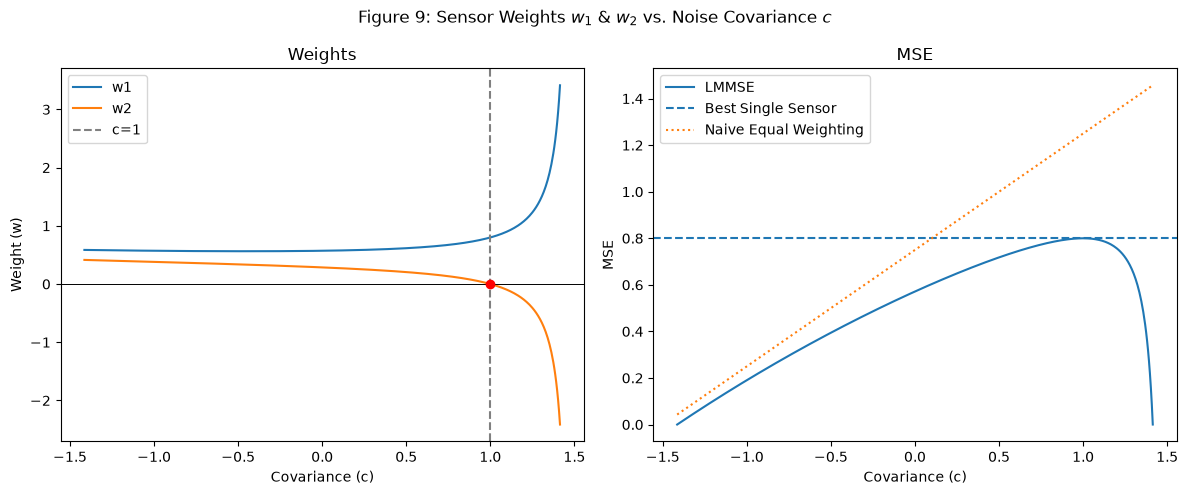

In [205]:

# Figure 9

range_of_c = np.linspace(-np.sqrt(2), np.sqrt(2), 500)

covar_xx = np.zeros((len(range_of_c), 2, 2))
covar_xx[:, 0, 0] = 5
covar_xx[:, 1, 1] = 6
covar_xx[:, 0, 1] = 4 + range_of_c
covar_xx[:, 1, 0] = 4 + range_of_c

sx_covar = np.array([4, 4])

weights = np.linalg.solve(covar_xx,np.broadcast_to(sx_covar.reshape(1, 2, 1),(len(range_of_c), 2, 1))).squeeze(-1)

w1 = weights[:, 0]
w2 = weights[:, 1]
mmse = 4 - np.sum(weights * sx_covar, axis=1)

single_sensor_mse = 4/5
equal_weight_mse = (3 + 2*range_of_c)/4

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.suptitle("Figure 9: Sensor Weights $w_1$ & $w_2$ vs. Noise Covariance $c$")

axes[0].plot(range_of_c, w1, label="w1")
axes[0].plot(range_of_c, w2, label="w2")
axes[0].axvline(1, linestyle="--", color="gray", label="c=1")
axes[0].axhline(0, color="black", linewidth=0.7)
axes[0].scatter(1, 0, color="red", zorder=5)
axes[0].set_title("Weights")
axes[0].set_xlabel("Covariance (c)")
axes[0].set_ylabel("Weight (w)")
axes[0].legend()

axes[1].plot(range_of_c, mmse, label="LMMSE")
axes[1].axhline(single_sensor_mse, linestyle="--",label="Best Single Sensor")
axes[1].plot(range_of_c, equal_weight_mse, linestyle=":",label="Naive Equal Weighting")
axes[1].set_title("MSE")
axes[1].set_xlabel("Covariance (c)")
axes[1].set_ylabel("MSE")
axes[1].legend()

plt.tight_layout()
plt.show()

**Figure 9 Interpretation**

In Figure 9, the sensor weights and MSE vary with increasing noise covariance. The sensor weight vs. noise covariance plot shows that the weight of the second sensor gradually approaches zero as $c$ increases to 1. When $c=1$, $w_1$ increases as $w_2$ reaches zero. Past $c=1$, the weight of the first sensor increases as the weight of the second sensor decreases rapidly. In the graph of MSE vs. covariance, the MSE of the best single sensor maintains a constant value of 0.8 as the MSE of the naive equal weighting maitains a linear increase with increasing covariance. The plot of LMMSE increases until reaching the maximum near 0.71, where the LMMSE decreases rapidly past this covariance. Both graphs show that the LMMSE changes the sensor weights with varying noise covariance to reduce estimated errors caused by noise.


## Bonus A: Generating correlated Gaussian vectors

Start with $z\sim\mathcal N(0,I)$. If $L$ is the Cholesky factor of $\Sigma$, then $\Sigma=LL^T$, so

$$E[Lz]=LE[z]=0,$$

$$\operatorname{Cov}(Lz)=L\operatorname{Cov}(z)L^T=LIL^T=\Sigma.$$

We can also use $\Sigma=V\Lambda V^T$ and set $x=V\Lambda^{1/2}z$. In that case,

$$\operatorname{Cov}(x)=V\Lambda^{1/2}I\Lambda^{1/2}V^T=V\Lambda V^T=\Sigma.$$

The code uses standard normal samples to test both methods with the $2\times2$ and $4\times4$ covariance matrices. It compares the estimated covariance matrices with the target matrices.


In [206]:
def samples_from_factor(Sigma, N, rng, method):
    d = Sigma.shape[0]
    z = rng.standard_normal(size=(N, d))
    if method == "Cholesky":
        factor = np.linalg.cholesky(Sigma)
    elif method == "Eigendecomposition":
        eigenvalues, eigenvectors = np.linalg.eigh(Sigma)
        factor = eigenvectors @ np.diag(np.sqrt(eigenvalues))
    else:
        raise ValueError("Unknown method")
    return z @ factor.T

Sigma2 = np.array([[4.0, 2.0], [2.0, 4.0]])
bonus_results = []
for matrix_name, target_cov in [("2x2", Sigma2), ("4x4", Sigma4)]:
    print(f"{matrix_name} target covariance:\n{target_cov}")
    for method in ["Cholesky", "Eigendecomposition"]:
        errors = []
        estimated_cov = None
        for trial in range(6):
            samples = samples_from_factor(target_cov, 50_000, rng_bonus_a, method)
            _, estimated_cov = sample_mean_cov(samples)
            errors.append(np.linalg.norm(estimated_cov-target_cov, ord="fro"))
        errors = np.array(errors)
        bonus_results.append({
            "target covariance": matrix_name, "method": method,
            "mean Frobenius error": errors.mean(),
            "standard error of mean": errors.std(ddof=1)/np.sqrt(len(errors)),
        })
        last_error = np.linalg.norm(estimated_cov-target_cov, ord="fro")
        print(f"{method} estimate:\n{np.array2string(estimated_cov, precision=4)}")
        print(f"Frobenius difference = {last_error:.6f}\n")


2x2 target covariance:
[[4. 2.]
 [2. 4.]]
Cholesky estimate:
[[3.9956 2.023 ]
 [2.023  4.0347]]
Frobenius difference = 0.047727

Eigendecomposition estimate:
[[4.0142 2.0062]
 [2.0062 3.981 ]]
Frobenius difference = 0.025290

4x4 target covariance:
[[4. 2. 1. 0.]
 [2. 5. 2. 1.]
 [1. 2. 3. 1.]
 [0. 1. 1. 2.]]
Cholesky estimate:
[[ 3.9866  2.0314  1.0005 -0.0097]
 [ 2.0314  5.0627  2.004   0.9963]
 [ 1.0005  2.004   2.9794  0.9959]
 [-0.0097  0.9963  0.9959  2.0086]]
Frobenius difference = 0.082855

Eigendecomposition estimate:
[[ 4.0471  2.0129  0.9789 -0.0286]
 [ 2.0129  5.0067  1.9889  0.9848]
 [ 0.9789  1.9889  2.9765  0.9995]
 [-0.0286  0.9848  0.9995  1.9897]]
Frobenius difference = 0.080509



In [207]:
bonus_table = pd.DataFrame(bonus_results)
print(bonus_table.to_string(index=False, float_format=lambda v: f"{v:.6f}"))

target covariance             method  mean Frobenius error  standard error of mean
              2x2           Cholesky              0.038014                0.005331
              2x2 Eigendecomposition              0.056462                0.015889
              4x4           Cholesky              0.072507                0.009186
              4x4 Eigendecomposition              0.074754                0.006509


In [208]:
singular_cov = np.array([[1.0, 1.0], [1.0, 1.0]])
print("Singular matrix eigenvalues:", np.linalg.eigvalsh(singular_cov))
try:
    np.linalg.cholesky(singular_cov)
    print("Cholesky unexpectedly completed; verify rounding / numerical definiteness.")
except np.linalg.LinAlgError as error:
    print("Cholesky fails on the singular matrix:", error)


Singular matrix eigenvalues: [0. 2.]
Cholesky fails on the singular matrix: Matrix is not positive definite


**Bonus A results.** Both methods give sample covariance matrices close to the target matrices, and the table shows the differences and their standard errors. Cholesky is usually cheaper because it does not need to calculate eigenvectors. Both factorizations take about $O(d^3)$ work, and applying either one to $N$ samples takes about $O(Nd^2)$.

Cholesky fails for the singular matrix because the usual Cholesky factorization needs a positive-definite matrix, and this matrix has a zero eigenvalue.


# Bonus B: Principal Components on Real Data
The dataset we are using is the built-in Stackloss dataset from the Python library statsmodels. The Stackloss dataset consists of four variables with 21 observations determining measurements from an industrial plant that produces nitric acid by oxidizing ammonia.


Stackloss Dataset:
   STACKLOSS  AIRFLOW  WATERTEMP  ACIDCONC
0       42.0     80.0       27.0      89.0
1       37.0     80.0       27.0      88.0
2       37.0     75.0       25.0      90.0
3       28.0     62.0       24.0      87.0
4       18.0     62.0       22.0      87.0
Original Fraction of Total Variance: 95.95%
Standardized Fraction of Total Variance: 93.29%
Difference in Fraction of Total Variance: 2.67%
Original Variances: [103.4619  84.0571   9.9905  28.7143]
Standardized Variances: [1. 1. 1. 1.]


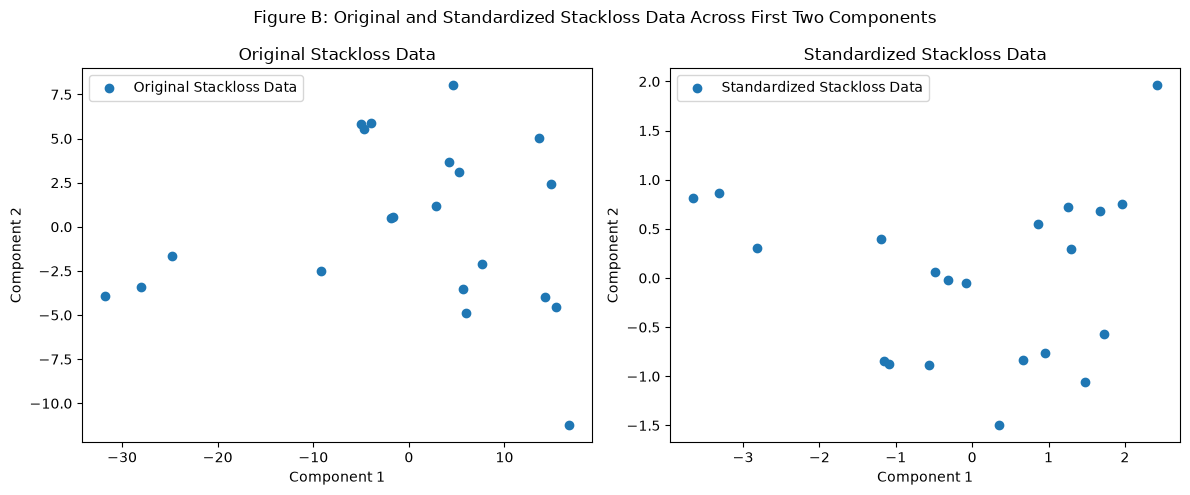

In [209]:
import statsmodels.api as sm

stackloss = sm.datasets.stackloss.load_pandas()
df = stackloss.data
X = df.to_numpy()

print("Stackloss Dataset:")
print(df.head())

mean, covariance = mp3lib.sample_mean_cov(X)

eigenvalues, eigenvectors = np.linalg.eigh(covariance)
eigenvalues = eigenvalues[::-1]
eigenvectors = eigenvectors[:, ::-1]

variance = np.sum(eigenvalues[:2]) / np.sum(eigenvalues)

centered_data = X - mean
pca = np.dot(centered_data, eigenvectors[:, :2])

print(f"Original Fraction of Total Variance: {variance:.2%}")

std_col = (X - mean) / np.std(X, axis=0, ddof=1)
std_mean, std_covariance = mp3lib.sample_mean_cov(std_col)
std_eigenval, std_eigenvectors = np.linalg.eigh(std_covariance)

sorted_std_values = std_eigenval[::-1]
sorted_std_vectors = std_eigenvectors[:, ::-1]

std_variance = np.sum(sorted_std_values[:2]) / np.sum(sorted_std_values)
pca_standardized = np.dot(std_col - std_mean, sorted_std_vectors[:, :2])

print(f"Standardized Fraction of Total Variance: {std_variance:.2%}")

diff = variance - std_variance
print(f"Difference in Fraction of Total Variance: {diff:.2%}")

print("Original Variances:", np.round(np.diag(covariance), 4))
print("Standardized Variances:", np.round(np.diag(std_covariance), 4))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

fig.suptitle("Figure B: Original and Standardized Stackloss Data Across First Two Components")

axes[0].scatter(pca[:, 0], pca[:, 1], label="Original Stackloss Data")
axes[0].set_title("Original Stackloss Data")
axes[0].set_xlabel("Component 1")
axes[0].set_ylabel("Component 2")
axes[0].legend()

axes[1].scatter(pca_standardized[:, 0], pca_standardized[:, 1], label="Standardized Stackloss Data")
axes[1].set_title("Standardized Stackloss Data")
axes[1].set_xlabel("Component 1")
axes[1].set_ylabel("Component 2")
axes[1].legend()

plt.tight_layout()
plt.show()

**Figure B Interpretation**

In the plots for Figure B, the original and standardized Stackloss datasets are projected into their first two components. The data points vary in their distribution between the two plots, which shows that standardizing the dataset impacts how the data is projected onto the principal components. Standardizing the Stackloss variables produces an identical variance of 1, so variables with smaller variances in the original dataset contribute a significant impact on the distribution onto the principal components.

**Answer Analysis**

In the analysis of the Stackloss dataset, the first two components capture 95.95% of the total variance in original dataset and 93.29% of the total variance in the standardized dataset. The answer changes because 4 variables in the original dataset have different variances.Variables with larger variances are represented more in the first two principal components. However, standardizing the Stackloss dataset produced in a variance of 1 for all four variables. As a result, the identical variance between Stackloss variance allows all variables to be analyzed without favoring variables with larger variance. Because of this, we trust the standardized version as standardization prevents results largely determined by varying variance values.


In [210]:
end_time = time.time()
total_time = end_time - start_time

if total_time < 60:
    print(f"Total Notebook Runtime: {total_time:.2f} seconds")
else:
    minutes, seconds = divmod(total_time, 60)
    print(f"Total Notebook Runtime: {int(minutes)} min {seconds:.2f} sec")

Total Notebook Runtime: 16.21 seconds
